In [2]:
%pip install sidetable
%conda install -c conda-forge --yes scienceplots

Note: you may need to restart the kernel to use updated packages.
Channels:
 - conda-forge
 - defaults
Platform: osx-arm64
Solving environment: done

# All requested packages already installed.


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
from configparser import ConfigParser
from matplotlib import pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import scienceplots
import seaborn as sns
import sidetable

In [3]:
plt.style.use('science')

In [4]:
os.getcwd()

'/Users/janik/source/urban-mobility-simulation/resources/scripts/simulation_analysis'

In [5]:
os.chdir("../../../")
os.getcwd()

'/Users/janik/source/urban-mobility-simulation'

In [6]:
from simulation.helper.time import SimulationTimeConverter

In [7]:
# Read args
parser = ConfigParser()
parser.read("resources/configurations/shared-charging.ini")

['resources/configurations/shared-charging.ini']

In [8]:
runs = pd.read_csv("data/output/run_configs.csv")
runs

,timestamp,experiment,duration_sim_min,duration_real_sec,n_vehicles,n_charging_stations,capacity_per_station,kW,seed
0,20240809_18:30:34,shared_charging.py,1440,332.849933,500,16,10,50.0,43
1,20240809_21:20:09,shared_charging.py,10080,2603.698136,500,16,5,22.0,43
2,20240809_22:15:47,single_infra.py,10080,574.578821,500,16,5,22.0,43
3,20240810_00:24:23,shared_charging.py,10080,613.348294,500,16,5,22.0,43


In [9]:
RUN_UNCOORDINATED = "20240809_22:15:47"
RUN_COORDINATED = "20240810_00:24:23"

In [10]:
SIM_DAYS = parser.getint("EXPERIMENT_MANAGEMENT", "END_TIME") // 1440 + 1

## Auction

In [11]:
auction_tracking = pd.read_csv(f"data/output/tracking/{RUN_COORDINATED}_auction.csv")

In [12]:
auction_tracking

,time,participant_id,location,_bids,_result
0,105,0,872664c1affffff,"[(1, 0.08790172118519632, 0), (1, 0.4334268850...","(5, 0.0)"
1,120,0,872664c1effffff,"[(1, 0.02402694267025843, 0), (1, 0.0657690152...","(5, 0.0)"
2,120,1,872664c13ffffff,"[(1, 0.24710031293215057, 1), (1, 0.2534417678...","(5, 0.0)"
3,180,0,872664cacffffff,"[(1, 0.016292310325897563, 0), (1, 0.063372410...","(2, 0.1141399504376937)"
4,180,1,872664cacffffff,"[(1, 0.016292310325897563, 1), (1, 0.063372410...","(3, 0.1141399504376937)"
...,...,...,...,...,...
222,9660,0,872664c1effffff,"[(1, 0.08989707087779013, 0), (1, 0.5244484965...","(2, 1.0)"
223,9705,0,872664c1affffff,"[(1, 0.08790172118519632, 0), (1, 0.4334268850...","(2, 1.0)"
224,9930,1,872664c16ffffff,"[(1, 0.08989707087779013, 1), (1, 0.5244484965...","(2, 1.0)"
225,9960,0,872664c13ffffff,"[(1, 0.02938246848631353, 0), (1, 0.1205181529...","(3, 1.0)"


In [13]:
# rename time axis
auction_tracking['timestamp'] = pd.to_datetime(auction_tracking['time'].apply(SimulationTimeConverter.as_datetime))

In [14]:
auction_tracking['_result.clearing_price'] = auction_tracking['_result'].apply(lambda x: eval(x)[1])
auction_tracking['_result.capacity'] = auction_tracking['_result'].apply(lambda x: eval(x)[0])

auction_tracking['_bids.total_capacity'] = auction_tracking['_bids'].apply(lambda x: sum([b[0] for b in eval(x)]))
auction_tracking['_bids.mean_bid'] = auction_tracking['_bids'].apply(lambda x: np.mean([b[1] for b in eval(x)]))

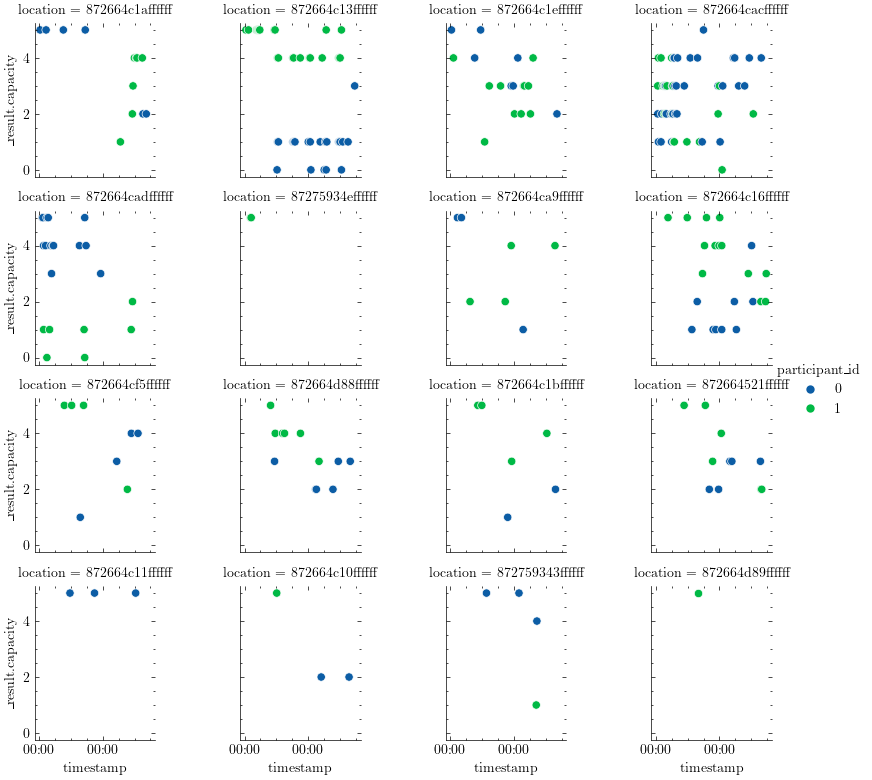

In [15]:
auction_tracking.sort_values(by=['time', 'location'], inplace=True)
g = sns.relplot(data=auction_tracking, x="timestamp", y="_result.capacity", hue="participant_id", col="location", col_wrap=4, kind="scatter", height=2)

axes = g.axes.flat

for a in axes:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=4))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

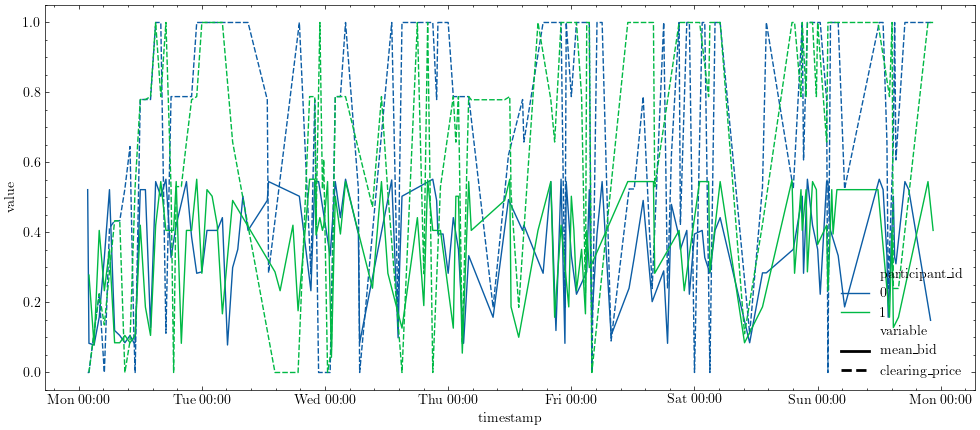

In [16]:
from matplotlib.lines import Line2D


fig, ax = plt.subplots(1,1, figsize=(12,5))

auction_tracking_long = auction_tracking.melt(id_vars=['timestamp', 'location', 'participant_id'], value_vars=['_result.clearing_price', '_bids.mean_bid'])
auction_tracking_long['variable'] = auction_tracking_long['variable'].astype('category')

sns.lineplot(data=auction_tracking_long, x="timestamp", y="value", hue="participant_id", style="variable", ax=ax)

handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([0], [0], color='black', lw=2, linestyle='solid'))
handles.append(Line2D([0], [0], color='black', lw=2, linestyle='dashed'))
labels.extend(['mean_bid', 'clearing_price'])

ax.legend(handles=handles, labels=labels)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

## Vehicles

In [17]:
vehicle_tracking_coordinated = pd.read_csv(f"data/output/tracking/{RUN_COORDINATED}_vehicles.csv")

In [18]:
vehicle_tracking_coordinated['_state'].apply(lambda x: set(eval(x))).value_counts()

_state
{1, 2, 3, 4, 5, 1003}          5562
{1, 2, 3, 4, 5, 1001, 1003}    4106
{1, 2, 3, 4, 1003}             3081
{1, 2, 3, 4, 1001, 1003}       2840
{1, 2, 1003, 4}                 714
{1, 2, 1003}                    682
{1, 2, 4, 1001, 1003}           681
{1, 2, 1003, 1001}              613
{1, 2, 3, 1003}                 368
{1, 2, 3, 1001, 1003}           337
{1, 2, 4, 5, 1003}              186
{1, 2, 3, 4, 5}                 182
{1, 2, 4, 5, 1001, 1003}        168
{1, 2, 3, 4, 5, 1001}           126
{1, 2, 3, 5, 1003}               87
{1, 2, 3, 5, 1001, 1003}         85
{1, 2}                           61
{1, 2, 1003, 5}                  60
{1, 2, 5, 1001, 1003}            56
{1, 2, 3, 4}                     50
{1, 2, 1001}                     48
{1, 2, 3, 4, 1001}               32
{1, 2, 3}                        11
{1, 2, 3, 1001}                   9
{1, 2, 3, 5}                      4
{1}                               4
{1, 2, 3, 5, 1001}                2
{1, 1001}            

In [19]:
RECHARGE_THRESHOLD = 25 # ATTENTION: This is an approximation, we use dynamic ones per hour # TODO: use dynamic from config

vehicle_tracking_coordinated['fleet_average_SOC'] = vehicle_tracking_coordinated['_current_state_of_charge'].apply(lambda x: np.mean(eval(x)))
vehicle_tracking_coordinated['fleet_number_low_SOC'] = vehicle_tracking_coordinated['_current_state_of_charge'].apply(lambda x: np.count_nonzero(np.array(eval(x))< RECHARGE_THRESHOLD))

In [20]:
# rename time axis
vehicle_tracking_coordinated.rename(columns={'time': 'simtime'}, inplace=True)
vehicle_tracking_coordinated['time'] = pd.to_datetime(vehicle_tracking_coordinated['simtime'].apply(SimulationTimeConverter.as_datetime))

# vehicle_tracking_coordinated['timestamp'] = vehicle_tracking_coordinated['time'].dt.strftime("%H:%M")

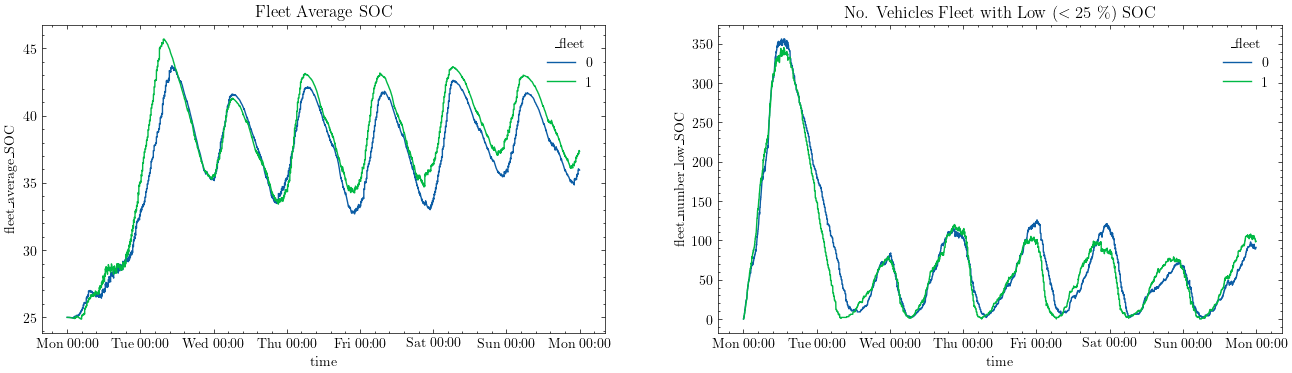

In [21]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (16, 4))

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_average_SOC', hue='_fleet', ax = ax[0])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_number_low_SOC', hue='_fleet', ax = ax[1])

ax[0].set_title('Fleet Average SOC')
ax[1].set_title(f'No. Vehicles Fleet with Low ($< {RECHARGE_THRESHOLD}$ \%) SOC')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

plt.show()

In [22]:
INITIALIZED = 0
PARKING = 1
DRIVING = 2
RELOCATING = 3
CHARGING = 4
PRE_SERVICE = 5
ONLINE = 6  # When the driver is online
OFFLINE = 7  # When the driver is offline
SOME_STATE = 1002
RESERVED = 1001
MOVING_TO_PICK_UP_POS = 1003

In [23]:
vehicle_tracking_coordinated['_state_PARKING'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PARKING))

vehicle_tracking_coordinated['_state_CHARGING'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == CHARGING))

vehicle_tracking_coordinated['_state_DRIVING'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == DRIVING))

vehicle_tracking_coordinated['_state_RELOCATING'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RELOCATING))

vehicle_tracking_coordinated['_state_PRE_SERVICE'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PRE_SERVICE))

vehicle_tracking_coordinated['_state_MOVING_TO_PICK_UP_POS'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == MOVING_TO_PICK_UP_POS))

vehicle_tracking_coordinated['_state_RESERVED'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RESERVED))

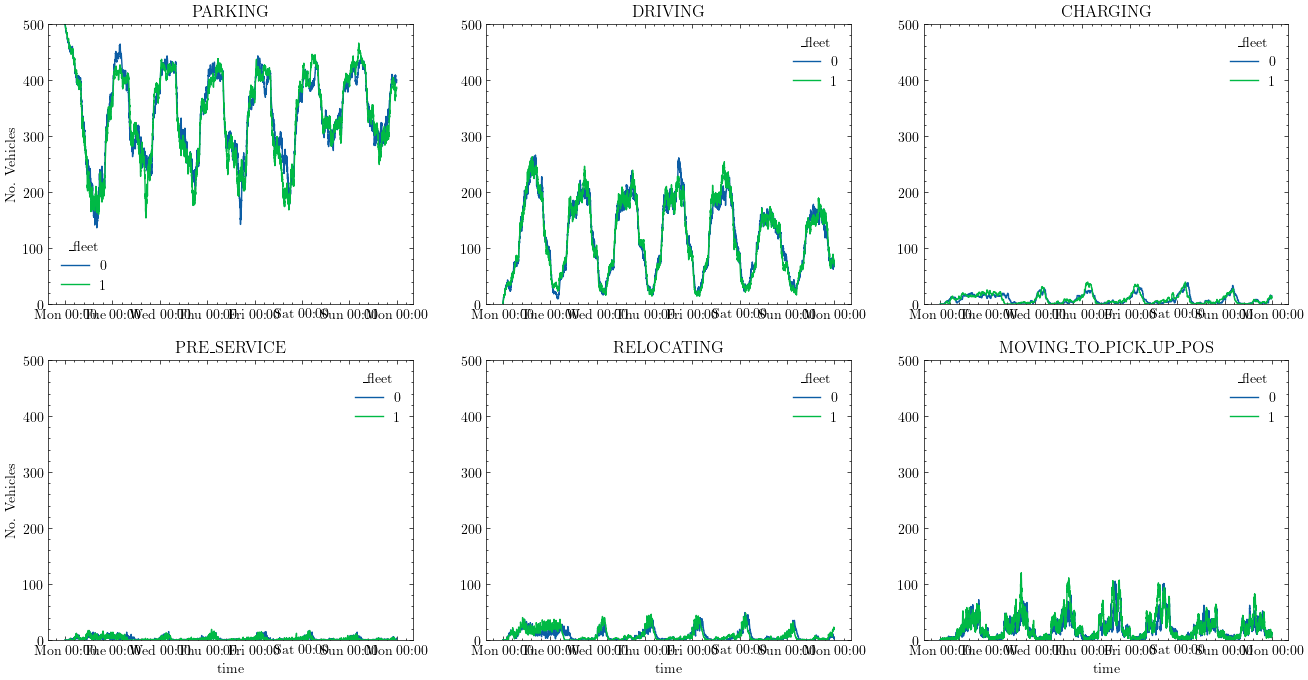

In [24]:
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(16, 8))
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_PARKING', hue='_fleet', ax=ax[0][0])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_DRIVING', hue='_fleet', ax=ax[0][1])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_CHARGING', hue='_fleet', ax=ax[0][2])

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_PRE_SERVICE', hue='_fleet', ax=ax[1][0])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_RELOCATING', hue='_fleet', ax=ax[1][1])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_MOVING_TO_PICK_UP_POS', hue='_fleet', ax=ax[1][2])

ax[0][0].set_title('PARKING')
ax[0][1].set_title('DRIVING')
ax[0][2].set_title('CHARGING')

ax[1][0].set_title('PRE_SERVICE')
ax[1][1].set_title('RELOCATING')
ax[1][2].set_title('MOVING_TO_PICK_UP_POS')


for aa in ax:
    for i, a in enumerate(aa):
        a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
        a.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))


        a.set_ylabel('No. Vehicles')
        a.set_ylim(0, parser.getint("EXPERIMENT_MANAGEMENT", "N_CARS"))
        a.yaxis.label.set_visible(False) if i > 0 else None

for a in ax[0]:
    a.xaxis.label.set_visible(False)

## Charging Stations

In [25]:
charging_station_tracking_coordinated = pd.read_csv(f"data/output/tracking/{RUN_COORDINATED}_charging_stations.csv")

In [26]:
CHARGING_STATION_CAPACITY = parser.getint("CHARGING_INFRASTRUCTURE", "CHARGING_STATION_CAPACITY")

In [27]:
charging_station_tracking_coordinated['utilization'] = charging_station_tracking_coordinated['_plugs.count'] / CHARGING_STATION_CAPACITY

charging_station_tracking_coordinated['system_wide_utilization'] = charging_station_tracking_coordinated.groupby('time')['utilization'].transform('mean')

In [28]:
# rename time axis
charging_station_tracking_coordinated['time'] = pd.to_datetime(charging_station_tracking_coordinated['time'].apply(SimulationTimeConverter.as_datetime))

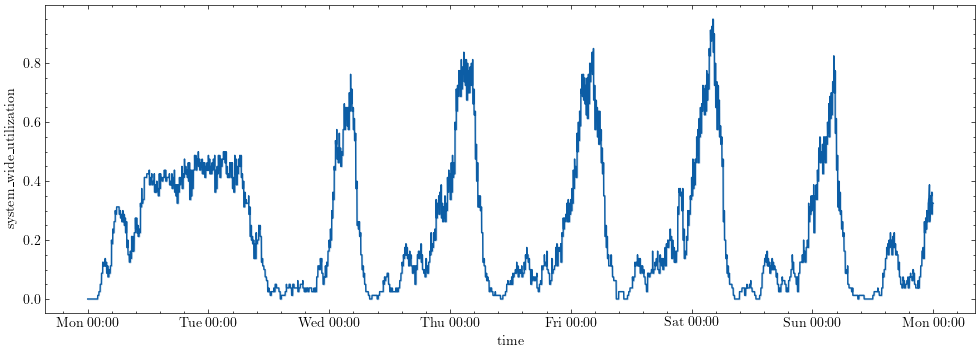

In [29]:
fig, ax = plt.subplots(1,1, figsize=(12,4))

sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='system_wide_utilization', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

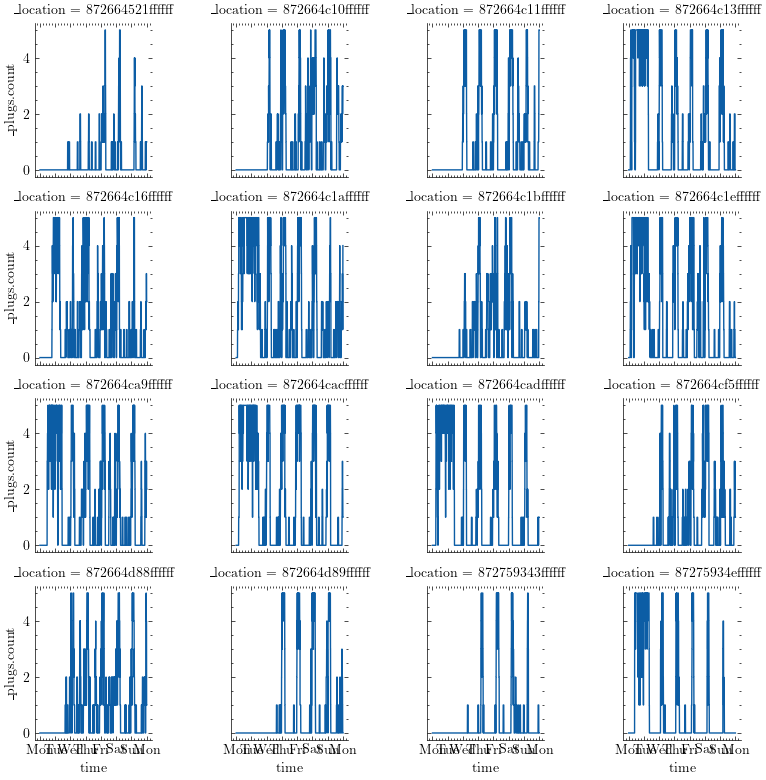

In [30]:
charging_station_tracking_coordinated.sort_values(by=['time', '_location'], inplace=True)
g = sns.relplot(
    data=charging_station_tracking_coordinated, x='time', y='_plugs.count', col='_location', kind='line', col_wrap=4, height=2)

axes = g.axes.flat

for a in axes:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

## Transactions

In [31]:
transactions_fleet_0 = pd.read_csv(f"data/output/transactions/{RUN_COORDINATED}_fleet_0_transactions.csv")
transactions_fleet_1 = pd.read_csv(f"data/output/transactions/{RUN_COORDINATED}_fleet_1_transactions.csv")

In [32]:
RESAMPLE_RATE = '1h'

In [33]:
transactions_fleet_0['timestamp'] = transactions_fleet_0['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_0['timestamp'] = pd.to_datetime(transactions_fleet_0['timestamp'])
transactions_fleet_0_resampled = transactions_fleet_0.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_1['timestamp'] = transactions_fleet_1['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_1['timestamp'] = pd.to_datetime(transactions_fleet_1['timestamp'])
transactions_fleet_1_resampled = transactions_fleet_1.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

In [34]:
# normalize
transactions_fleet_0_resampled = transactions_fleet_0_resampled.div(transactions_fleet_0_resampled.sum(axis=1), axis=0)

transactions_fleet_1_resampled = transactions_fleet_1_resampled.div(transactions_fleet_1_resampled.sum(axis=1), axis=0)

# rename time axis
# transactions_fleet_0_resampled['timestamp'] = transactions_fleet_0_resampled.index.strftime("%H:%M")
# transactions_fleet_0_resampled.set_index('timestamp', inplace=True)

# transactions_fleet_1_resampled['timestamp'] = transactions_fleet_1_resampled.index.strftime("%H:%M")
# transactions_fleet_1_resampled.set_index('timestamp', inplace=True)

In [35]:
transactions_fleet_0_resampled

state                    
state               Fulfilled    MISSED   REFUSED
timestamp                                        
2024-01-01 00:00:00  0.258065       NaN  0.741935
2024-01-01 01:00:00  0.416667       NaN  0.583333
2024-01-01 02:00:00  0.615385       NaN  0.384615
2024-01-01 03:00:00  0.659091       NaN  0.340909
2024-01-01 04:00:00  0.382716       NaN  0.617284
...                       ...       ...       ...
2024-01-07 19:00:00  0.537037  0.187831  0.275132
2024-01-07 20:00:00  0.627049  0.172131  0.200820
2024-01-07 21:00:00  0.509434  0.273585  0.216981
2024-01-07 22:00:00  0.557692  0.179487  0.262821
2024-01-07 23:00:00  0.395604  0.368132  0.236264

[168 rows x 3 columns]

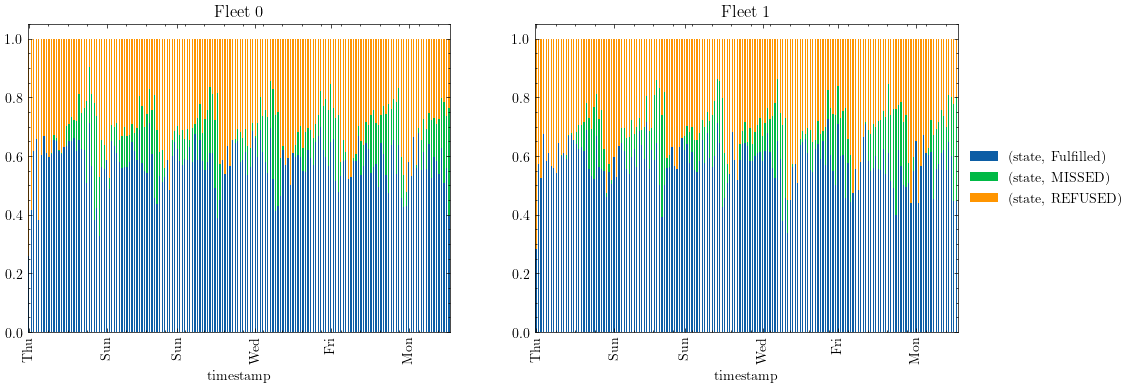

In [36]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

transactions_fleet_0_resampled.plot(kind = 'bar', stacked=True, ax=ax[0], legend=False)
transactions_fleet_1_resampled.plot(kind = 'bar', stacked=True, ax=ax[1], legend=True)

ax[1].legend(loc='center left', bbox_to_anchor=(1.0, 0.5))

ax[0].set_title('Fleet 0')
ax[1].set_title('Fleet 1')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

(0.0, 1.0)

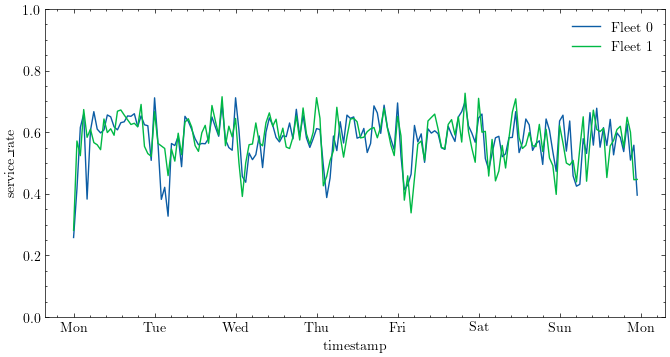

In [37]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 4))

transactions_fleet_0_resampled['service_rate'] = transactions_fleet_0_resampled[('state', 'Fulfilled')]
transactions_fleet_1_resampled['service_rate'] = transactions_fleet_1_resampled[('state', 'Fulfilled')]

# service_rate_mean = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].join(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')

sns.lineplot(data=transactions_fleet_0_resampled, x = transactions_fleet_0_resampled.index, y = 'service_rate', label='Fleet 0', ax=ax)
sns.lineplot(data=transactions_fleet_1_resampled, x = transactions_fleet_1_resampled.index, y = 'service_rate', label='Fleet 1', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

ax.set_ylim(0, 1.0)

### Vehilce Distance Travelled: Service vs. Operations

In [38]:
vehicle_tracking_coordinated['fleet_vdt'] = vehicle_tracking_coordinated['_vdt'].apply(lambda x: sum(eval(x)))

In [39]:
service_vdt_fleet_0 = transactions_fleet_0[transactions_fleet_0['state'] == 'Fulfilled'].resample(RESAMPLE_RATE, on = 'timestamp').agg({'distance': 'sum'})
service_vdt_fleet_1 = transactions_fleet_1[transactions_fleet_1['state'] == 'Fulfilled'].resample(RESAMPLE_RATE, on = 'timestamp').agg({'distance': 'sum'})

In [40]:
service_vdt_fleet_0['cumsum'] = service_vdt_fleet_0.cumsum()
service_vdt_fleet_1['cumsum'] = service_vdt_fleet_1.cumsum()

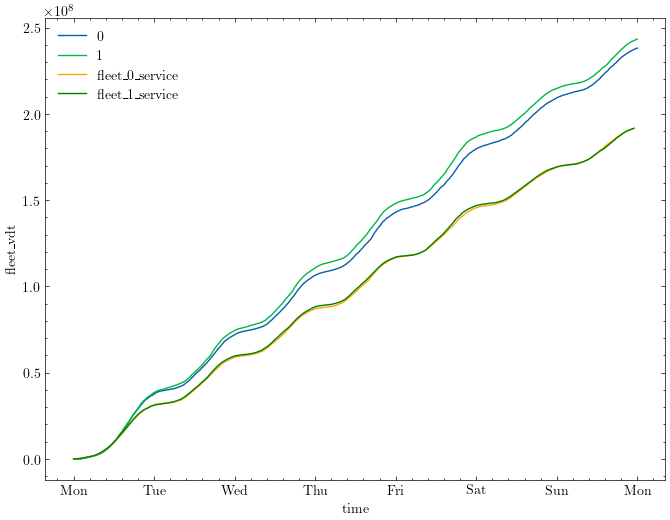

In [41]:
fig, ax = plt.subplots(1,1, figsize=(8, 6))

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_vdt', hue='_fleet', ax=ax)
sns.lineplot(data=service_vdt_fleet_0, x='timestamp', y='cumsum', color='orange', label='fleet_0_service', ax=ax)
sns.lineplot(data=service_vdt_fleet_1, x='timestamp', y='cumsum', color='green', label='fleet_1_service', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

In [42]:
# share of operations VDT (excl customer serving)
hourly_vdt = vehicle_tracking_coordinated.groupby('_fleet').resample(RESAMPLE_RATE, on = 'time').agg({'fleet_vdt': 'max'}).unstack(level=0).rename(columns={0: 'fleet_0_vdt_cumsum', 1: 'fleet_1_vdt_cumsum'}).droplevel(0, axis=1)

In [43]:
hourly_vdt = hourly_vdt.join(service_vdt_fleet_0)

hourly_vdt = hourly_vdt.join(service_vdt_fleet_1, rsuffix='_service_fleet_1')

hourly_vdt.rename(columns={'distance': 'distance_service_fleet_0', 'cumsum': 'cumsum_service_fleet_0'}, inplace=True)

hourly_vdt['fleet_0_ratio_of_empty_vdt'] = (hourly_vdt['fleet_0_vdt_cumsum'] - hourly_vdt['cumsum_service_fleet_0']) / hourly_vdt['fleet_0_vdt_cumsum']

hourly_vdt['fleet_1_ratio_of_empty_vdt'] = (hourly_vdt['fleet_1_vdt_cumsum'] - hourly_vdt['cumsum_service_fleet_1']) / hourly_vdt['fleet_1_vdt_cumsum']

In [44]:
hourly_vdt['fleet_0_vdt'] = hourly_vdt['fleet_0_vdt_cumsum'].diff().fillna(hourly_vdt['fleet_0_vdt_cumsum'].iloc[0])

hourly_vdt['fleet_1_vdt'] = hourly_vdt['fleet_1_vdt_cumsum'].diff().fillna(hourly_vdt['fleet_1_vdt_cumsum'].iloc[0])


In [45]:
hourly_vdt['fleet_0_ratio_of_empty_vdt'] = (hourly_vdt['fleet_0_vdt'] - hourly_vdt['distance_service_fleet_0']) / hourly_vdt['fleet_0_vdt']

hourly_vdt['fleet_1_ratio_of_empty_vdt'] = (hourly_vdt['fleet_1_vdt'] - hourly_vdt['distance_service_fleet_1']) / hourly_vdt['fleet_1_vdt']

In [46]:
hourly_vdt.head()

,fleet_0_vdt_cumsum,fleet_1_vdt_cumsum,distance_service_fleet_0,cumsum_service_fleet_0,distance_service_fleet_1,cumsum_service_fleet_1,fleet_0_ratio_of_empty_vdt,fleet_1_ratio_of_empty_vdt,fleet_0_vdt,fleet_1_vdt
time,,,,,,,,,,
2024-01-01 00:00:00,2.309414e+04,3.921459e+04,19116.433926,19116.433926,30899.452904,3.089945e+04,0.172239,0.212042,23094.140428,39214.586651
2024-01-01 01:00:00,1.376310e+05,1.155417e+05,100226.278160,119342.712086,85355.093907,1.162545e+05,0.124943,-0.118280,114536.886793,76327.137507
2024-01-01 02:00:00,4.088280e+05,3.523544e+05,265397.565145,384740.277230,188249.765600,3.045043e+05,0.021385,0.205069,271196.979208,236812.667344
2024-01-01 03:00:00,8.416604e+05,7.767720e+05,356171.189887,740911.467117,400636.870291,7.051412e+05,0.177115,0.056031,432832.421036,424417.610394
2024-01-01 04:00:00,1.211751e+06,1.269561e+06,223306.613109,964218.080227,373783.200493,1.078924e+06,0.396617,0.241494,370090.771012,492788.989635


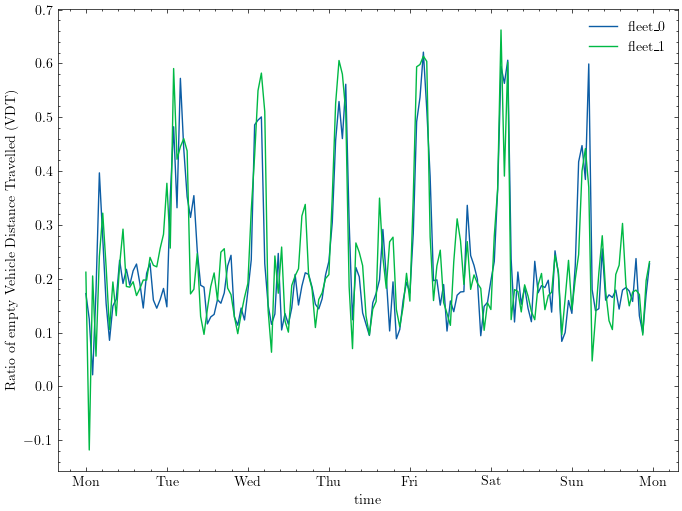

In [47]:
fig, ax = plt.subplots(1,1, figsize=(8, 6))

sns.lineplot(data=hourly_vdt, x='time', y='fleet_0_ratio_of_empty_vdt', label='fleet_0', ax=ax)
sns.lineplot(data=hourly_vdt, x='time', y='fleet_1_ratio_of_empty_vdt', label='fleet_1', ax=ax)

ax.set_ylabel('Ratio of empty Vehicle Distance Travelled (VDT)')

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

## Service Tasks

In [48]:
task_transactions_fleet_0 = pd.read_csv(f"data/output/transactions/{RUN_COORDINATED}_fleet_0_task_transactions.csv")

task_transactions_fleet_1 = pd.read_csv(f"data/output/transactions/{RUN_COORDINATED}_fleet_1_task_transactions.csv")

In [49]:
task_transactions_fleet_0['timestamp'] = task_transactions_fleet_0['start_time'].apply(SimulationTimeConverter.as_datetime)
task_transactions_fleet_0['timestamp'] = pd.to_datetime(task_transactions_fleet_0['timestamp'])

task_transactions_fleet_1['timestamp'] = task_transactions_fleet_1['start_time'].apply(SimulationTimeConverter.as_datetime)
task_transactions_fleet_1['timestamp'] = pd.to_datetime(task_transactions_fleet_1['timestamp'])

task_transactions_fleet_0['duration'] = task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['start_time']

task_transactions_fleet_1['duration'] = task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['start_time']

!! probably we should sanity-check why duration < waiting_time + charging_duration

In [50]:
task_transactions_fleet_0

,start_time,end_time,vehicle,state,fleet,charging_station,waiting_time,charging_duration,kWh_charged,timestamp,duration
0,106,180.0,6,TaskState.FINISHED,0,872664c1affffff,6.381589,60.00000,22.000000,2024-01-01 01:46:00,74.0
1,121,195.0,71,TaskState.FINISHED,0,872664c1effffff,9.610562,60.00000,22.000000,2024-01-01 02:01:00,74.0
2,121,210.0,22,TaskState.FINISHED,0,872664c1effffff,11.648111,60.00000,22.000000,2024-01-01 02:01:00,89.0
3,166,240.0,9,TaskState.FINISHED,0,872664c1affffff,5.745985,60.00000,22.000000,2024-01-01 02:46:00,74.0
4,121,240.0,66,TaskState.FINISHED,0,872664c1effffff,4.355205,60.00000,22.000000,2024-01-01 02:01:00,119.0
...,...,...,...,...,...,...,...,...,...,...,...
1571,10051,10080.0,395,TaskState.EXECUTING_RELOCATION,0,872664c11ffffff,-44.559429,NaN,NaN,2024-01-07 23:31:00,29.0
1572,10051,10080.0,489,TaskState.EXECUTING_CHARGING,0,872664c11ffffff,-36.798670,23.20133,8.507154,2024-01-07 23:31:00,29.0
1573,10066,10080.0,261,TaskState.EXECUTING_RELOCATION,0,872664c11ffffff,NaN,NaN,NaN,2024-01-07 23:46:00,14.0
1574,10066,10080.0,267,TaskState.EXECUTING_RELOCATION,0,872664c11ffffff,NaN,NaN,NaN,2024-01-07 23:46:00,14.0


In [51]:
display(task_transactions_fleet_0.value_counts(subset=['state']))
display(task_transactions_fleet_1.value_counts(subset=['state']))

state                         
TaskState.FINISHED                1555
TaskState.EXECUTING_CHARGING        14
TaskState.EXECUTING_RELOCATION       7
Name: count, dtype: int64

state                         
TaskState.FINISHED                1601
TaskState.EXECUTING_RELOCATION      19
TaskState.EXECUTING_CHARGING        13
Name: count, dtype: int64

<Axes: xlabel='charging_duration', ylabel='kWh_charged'>

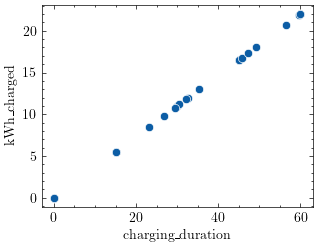

In [52]:
# check linearity
sns.scatterplot(data=task_transactions_fleet_0, x='charging_duration', y='kWh_charged')

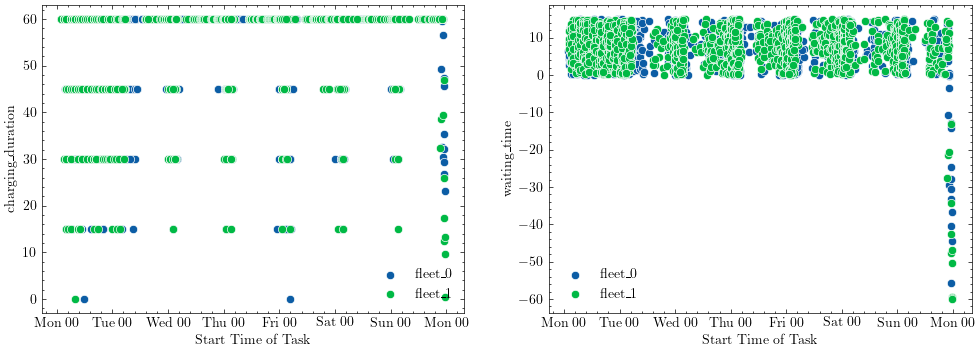

In [53]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

sns.scatterplot(data=task_transactions_fleet_0, x='timestamp', y='charging_duration', label='fleet_0', ax=ax[0])
sns.scatterplot(data=task_transactions_fleet_1, x='timestamp', y='charging_duration', label='fleet_1', ax=ax[0])

sns.scatterplot(data=task_transactions_fleet_0, x='timestamp', y='waiting_time', label='fleet_0', ax=ax[1])
sns.scatterplot(data=task_transactions_fleet_1, x='timestamp', y='waiting_time', label='fleet_1', ax=ax[1])

for a in ax:
    a.set_xlabel('Start Time of Task')
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a %H'))

In [54]:
hourly_tasks = pd.merge(
    task_transactions_fleet_0.resample('h', on='timestamp').agg({'fleet': 'count', 'waiting_time': 'mean', 'charging_duration': 'mean'}).rename(columns={'fleet': 'tasks_finished_fleet_0', 'waiting_time': 'avg_waiting_time_fleet_0', 'charging_duration': 'avg_charging_duration_fleet_0'}),
    task_transactions_fleet_1.resample('h', on='timestamp').agg({'fleet': 'count', 'waiting_time': 'mean', 'charging_duration': 'mean'}).rename(columns={'fleet': 'tasks_finished_fleet_1', 'waiting_time': 'avg_waiting_time_fleet_1', 'charging_duration': 'avg_charging_duration_fleet_1'}),
    how='outer',
    left_index=True,
    right_index=True
).fillna(0)

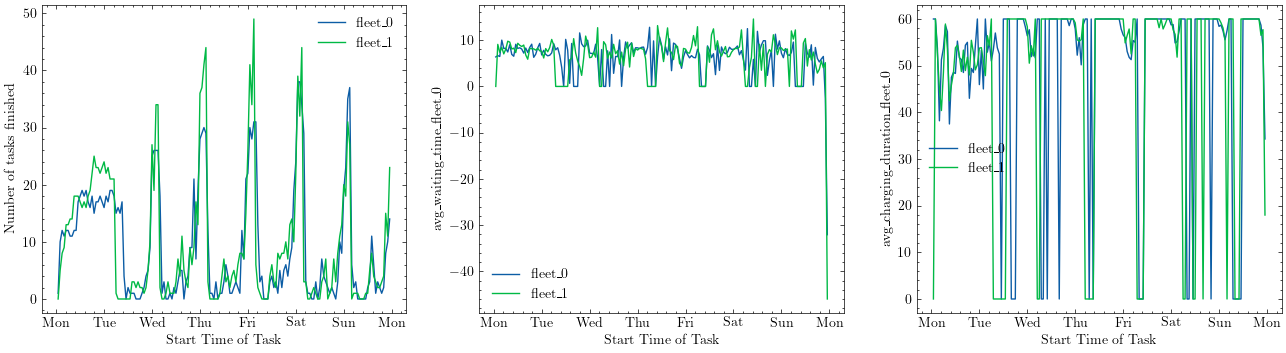

In [55]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))

sns.lineplot(data=hourly_tasks, x='timestamp', y='tasks_finished_fleet_0', label='fleet_0', ax=ax[0])
sns.lineplot(data=hourly_tasks, x='timestamp', y='tasks_finished_fleet_1', label='fleet_1', ax=ax[0])

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_0', label='fleet_0', ax=ax[1])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_1', label='fleet_1', ax=ax[1])

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_charging_duration_fleet_0', label='fleet_0', ax=ax[2])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_charging_duration_fleet_1', label='fleet_1', ax=ax[2])

ax[0].set_ylabel("Number of tasks finished")

for a in ax:
    a.set_xlabel('Start Time of Task')
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS + 1))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

In [56]:
date_range = range(0,parser.getint("EXPERIMENT_MANAGEMENT", "END_TIME"), 15)

hourly_events_fleet_0 = pd.DataFrame({'time': date_range, 'events_ongoing_fleet_0': [((task_transactions_fleet_0['start_time'] <= i) & (task_transactions_fleet_0['end_time'] > i)).sum() for i in date_range]})
hourly_events_fleet_0.set_index('time', inplace=True)

hourly_events_fleet_1 = pd.DataFrame({'time': date_range, 'events_ongoing_fleet_1': [((task_transactions_fleet_1['start_time'] <= i) & (task_transactions_fleet_1['end_time'] > i)).sum() for i in date_range]})
hourly_events_fleet_1.set_index('time', inplace=True)

hourly_events_ongoing = pd.merge(
    hourly_events_fleet_0,
    hourly_events_fleet_1,
    how='outer',
    left_index=True,
    right_index=True
).fillna(0)

hourly_events_ongoing.reset_index(inplace=True)

In [57]:
hourly_events_ongoing['timestamp'] = hourly_events_ongoing['time'].apply(SimulationTimeConverter.as_datetime)
hourly_events_ongoing['timestamp'] = pd.to_datetime(hourly_events_ongoing['timestamp'])

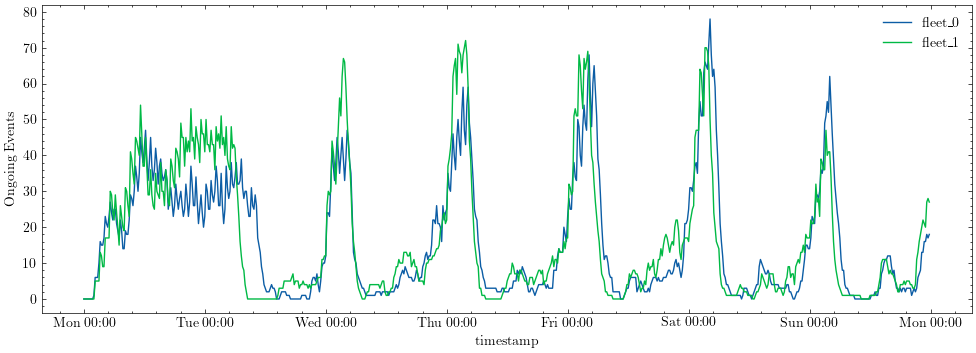

In [58]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(12, 4))

sns.lineplot(data=hourly_events_ongoing, x='timestamp', y='events_ongoing_fleet_0', label='fleet_0', ax=ax)
sns.lineplot(data=hourly_events_ongoing, x='timestamp', y='events_ongoing_fleet_1', label='fleet_1', ax=ax)

ax.set_ylabel('Ongoing Events')

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))


In [59]:
task_transactions_fleet_0['timeslot'] = (task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['charging_duration']) - ((task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['charging_duration']) % 15)

task_transactions_fleet_1['timeslot'] = (task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['charging_duration']) - ((task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['charging_duration']) % 15)

In [60]:
tasks_incl_price = pd.concat(
    [task_transactions_fleet_0,task_transactions_fleet_1]
    ).merge(
        auction_tracking[['time', '_result.clearing_price']], 
        how='left', 
        left_on = 'timeslot', 
        right_on = "time"
        )

In [61]:
kWh_price = parser.getfloat("AUTONOMOUS_CAR", "CHARGING_COST_PER_KWH")

tasks_incl_price['charging_cost'] = tasks_incl_price['kWh_charged'] * kWh_price

In [62]:
tasks_incl_price.head()

,start_time,end_time,vehicle,state,fleet,charging_station,waiting_time,charging_duration,kWh_charged,timestamp,duration,timeslot,time,_result.clearing_price,charging_cost
0,106,180.0,6,TaskState.FINISHED,0,872664c1affffff,6.381589,60.0,22.0,2024-01-01 01:46:00,74.0,120.0,120.0,0.00000,9.46
1,106,180.0,6,TaskState.FINISHED,0,872664c1affffff,6.381589,60.0,22.0,2024-01-01 01:46:00,74.0,120.0,120.0,0.00000,9.46
2,121,195.0,71,TaskState.FINISHED,0,872664c1effffff,9.610562,60.0,22.0,2024-01-01 02:01:00,74.0,135.0,NaN,NaN,9.46
3,121,210.0,22,TaskState.FINISHED,0,872664c1effffff,11.648111,60.0,22.0,2024-01-01 02:01:00,89.0,150.0,NaN,NaN,9.46
4,166,240.0,9,TaskState.FINISHED,0,872664c1affffff,5.745985,60.0,22.0,2024-01-01 02:46:00,74.0,180.0,180.0,0.11414,9.46


In [63]:
hourly_costs = tasks_incl_price.groupby('fleet').resample('1h', on='timestamp').agg({'charging_cost': 'sum', '_result.clearing_price': 'sum'}).reset_index()
hourly_costs.rename(columns={'_result.clearing_price': 'reservation_cost'}, inplace=True)

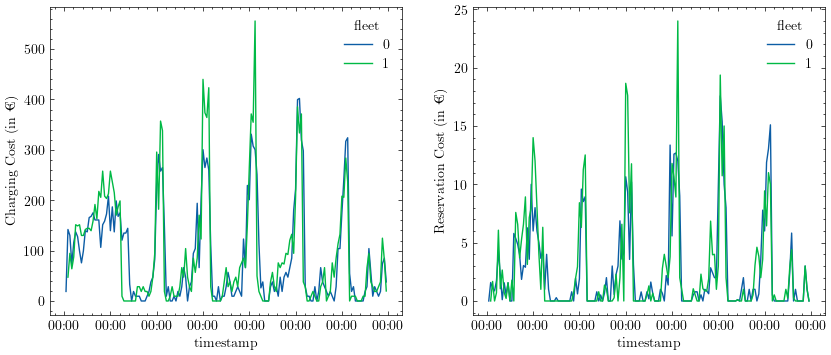

In [64]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

sns.lineplot(hourly_costs, x='timestamp', y='charging_cost', hue='fleet', ax=ax[0])
sns.lineplot(hourly_costs, x='timestamp', y='reservation_cost', hue='fleet', ax=ax[1])

ax[0].set_ylabel('Charging Cost (in €)')
ax[1].set_ylabel('Reservation Cost (in €)')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

## Benchmark: Single Infrastructure, No Coordination

In [65]:
charging_station_tracking_uncoordinated = pd.read_csv(f"data/output/tracking/{RUN_UNCOORDINATED}_charging_stations.csv")
vehicle_tracking_uncoordinated = pd.read_csv(f"data/output/tracking/{RUN_UNCOORDINATED}_vehicles.csv")

In [66]:
RECHARGE_THRESHOLD = 25 # ATTENTION: This is an approximation, we use dynamic ones per hour # TODO: use dynamic from config

vehicle_tracking_uncoordinated['fleet_average_SOC'] = vehicle_tracking_uncoordinated['_current_state_of_charge'].apply(lambda x: np.mean(eval(x)))
vehicle_tracking_uncoordinated['fleet_number_low_SOC'] = vehicle_tracking_uncoordinated['_current_state_of_charge'].apply(lambda x: np.count_nonzero(np.array(eval(x))< RECHARGE_THRESHOLD))

In [67]:
# rename time axis
vehicle_tracking_uncoordinated.rename(columns={'time': 'simtime'}, inplace=True)
vehicle_tracking_uncoordinated['time'] = pd.to_datetime(vehicle_tracking_uncoordinated['simtime'].apply(SimulationTimeConverter.as_datetime))

# vehicle_tracking_coordinated['timestamp'] = vehicle_tracking_coordinated['time'].dt.strftime("%H:%M")

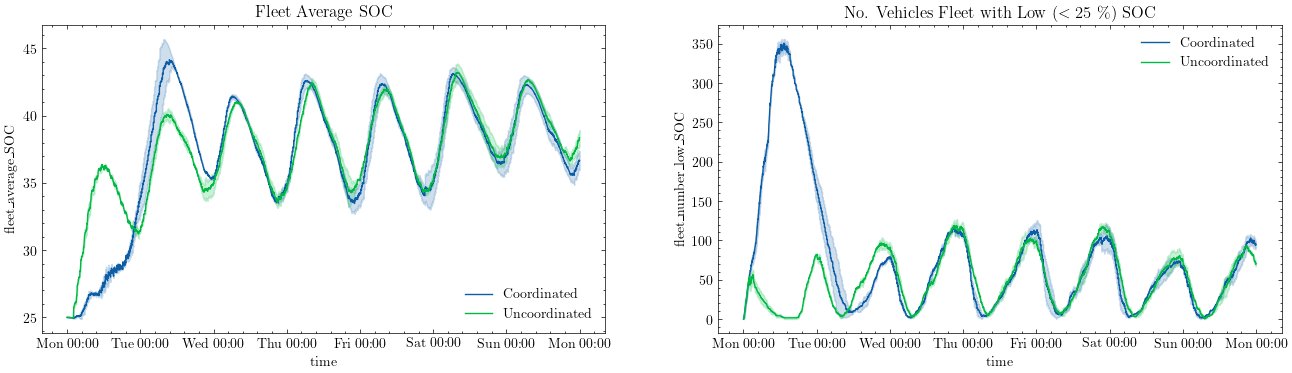

In [68]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (16, 4))

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_average_SOC', ax = ax[0], label='Coordinated')
sns.lineplot(data=vehicle_tracking_uncoordinated, x='time', y='fleet_average_SOC', ax = ax[0], label='Uncoordinated')

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_number_low_SOC', ax = ax[1], label='Coordinated')
sns.lineplot(data=vehicle_tracking_uncoordinated, x='time', y='fleet_number_low_SOC', ax = ax[1], label='Uncoordinated')

ax[0].set_title('Fleet Average SOC')
ax[1].set_title(f'No. Vehicles Fleet with Low ($< {RECHARGE_THRESHOLD}$ \%) SOC')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

plt.show()

In [69]:
charging_station_tracking_uncoordinated['utilization'] = charging_station_tracking_uncoordinated['_plugs.count'] / CHARGING_STATION_CAPACITY

charging_station_tracking_uncoordinated['system_wide_utilization'] = charging_station_tracking_uncoordinated.groupby('time')['utilization'].transform('mean')

In [70]:
# rename time axis
charging_station_tracking_uncoordinated['time'] = pd.to_datetime(charging_station_tracking_uncoordinated['time'].apply(SimulationTimeConverter.as_datetime))

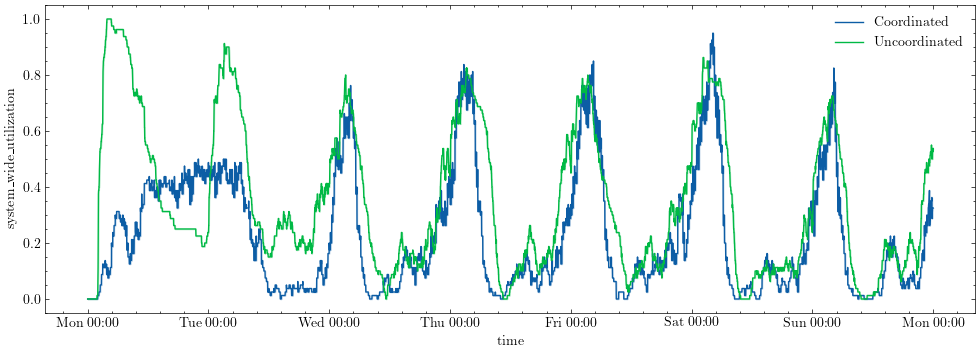

In [71]:
fig, ax = plt.subplots(1,1, figsize=(12,4))

sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='system_wide_utilization', label= 'Coordinated', ax=ax)
sns.lineplot(data=charging_station_tracking_uncoordinated, x='time', y='system_wide_utilization', label= 'Uncoordinated', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

In [72]:
transactions_fleet_0_uncoordinated = pd.read_csv(f"data/output/transactions/{RUN_UNCOORDINATED}_fleet_0_transactions.csv")
transactions_fleet_1_uncoordinated = pd.read_csv(f"data/output/transactions/{RUN_UNCOORDINATED}_fleet_1_transactions.csv")

In [89]:
transactions_fleet_0_uncoordinated['timestamp'] = transactions_fleet_0_uncoordinated['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_0_uncoordinated['timestamp'] = pd.to_datetime(transactions_fleet_0_uncoordinated['timestamp'])
transactions_fleet_0_uncoordinated_resampled = transactions_fleet_0_uncoordinated.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_1_uncoordinated['timestamp'] = transactions_fleet_1_uncoordinated['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_1_uncoordinated['timestamp'] = pd.to_datetime(transactions_fleet_1_uncoordinated['timestamp'])
transactions_fleet_1_uncoordinated_resampled = transactions_fleet_1_uncoordinated.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

# normalize
transactions_fleet_0_uncoordinated_resampled = transactions_fleet_0_uncoordinated_resampled.div(transactions_fleet_0_uncoordinated_resampled.sum(axis=1), axis=0)

transactions_fleet_1_uncoordinated_resampled = transactions_fleet_1_uncoordinated_resampled.div(transactions_fleet_1_uncoordinated_resampled.sum(axis=1), axis=0)

# calc service rate, per fleet and overall
transactions_fleet_0_uncoordinated_resampled['service_rate'] = transactions_fleet_0_uncoordinated_resampled[('state', 'Fulfilled')]
transactions_fleet_1_uncoordinated_resampled['service_rate'] = transactions_fleet_1_uncoordinated_resampled[('state', 'Fulfilled')]

service_rate_coordinated = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')
service_rate_uncoordinated = transactions_fleet_0_uncoordinated_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_uncoordinated_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')

service_rate_coordinated['service_rate'] = service_rate_coordinated[['service_rate_x', 'service_rate_y']].apply('mean', axis=1)
service_rate_uncoordinated['service_rate'] = service_rate_uncoordinated[['service_rate_x', 'service_rate_y']].apply('mean', axis=1)

/var/folders/tm/rzk5w14x43s6q7sgpkq2r7wc0000gn/T/ipykernel_39339/1529823247.py:18: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  service_rate_coordinated = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')
/var/folders/tm/rzk5w14x43s6q7sgpkq2r7wc0000gn/T/ipykernel_39339/1529823247.py:19: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  service_rate_uncoordinated = transactions_fleet_0_uncoordinated_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_uncoordinated_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')


(0.0, 1.0)

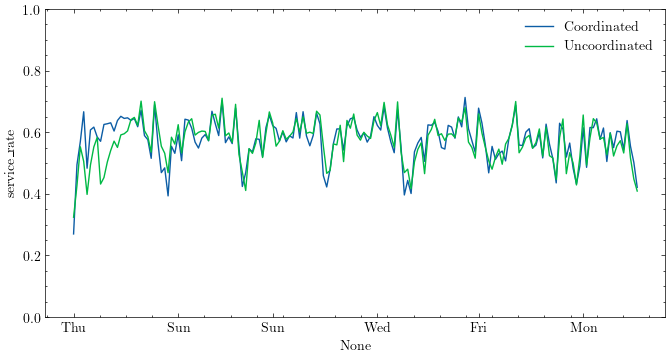

In [90]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 4))

sns.lineplot(data=service_rate_coordinated, x = service_rate_coordinated.index, y = 'service_rate', label='Coordinated', ax=ax)
sns.lineplot(data=service_rate_uncoordinated, x = service_rate_uncoordinated.index, y = 'service_rate', label='Uncoordinated', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

ax.set_ylim(0, 1.0)

In [ ]:
# TODO: empty VDT

### compare one day with Anthony's results

In [ ]:
benchmark_no_coordination = pd.read_csv("data/output/benchmarks/time_related_kpi_500.csv")

In [111]:
benchmark_no_coordination

,timestamp,all_vehicles_avg_SOC,all_vehicles_waiting_times,all_stations_utilization_rate
0,5,24.999690,"[[0.0], [0.0], [0.0], [0.0], [0.0], [], [0.0],...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]"
1,10,24.999282,"[[0.0], [0.0], [0.0], [0.0], [0.0], [], [0.0],...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]"
2,15,24.998242,"[[0.0], [0.0], [0.0], [0.0], [0.0], [], [0.0],...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]"
3,20,24.996023,"[[0.0], [0.0], [0.0], [0.0], [0.0], [], [0.0],...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]"
4,25,24.993021,"[[0.0], [0.0], [0.0], [0.0], [0.0], [], [0.0],...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]"
...,...,...,...,...
282,1415,31.071695,"[[0.0], [0.0], [0.0], [0.0], [0.0], [], [0.0],...","[0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.1..."
283,1420,31.038341,"[[0.0], [0.0], [0.0], [0.0], [0.0], [], [0.0],...","[0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.1..."
284,1425,31.016514,"[[0.0], [0.0], [0.0], [0.0], [0.0], [], [0.0],...","[0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.1..."
285,1430,31.009206,"[[0.0], [0.0], [0.0], [0.0], [0.0], [], [0.0],...","[0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.1..."


<Axes: xlabel='timestamp'>

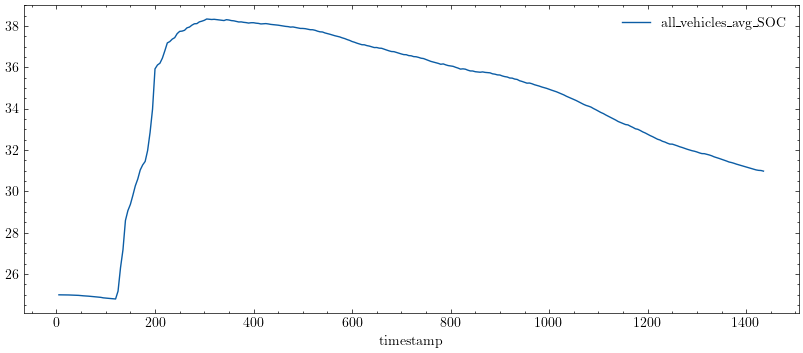

In [112]:
benchmark_no_coordination.plot(x='timestamp', y='all_vehicles_avg_SOC', figsize=(10, 4))

In [113]:
benchmark_no_coordination['charging_utilization'] = benchmark_no_coordination['all_stations_utilization_rate'].apply(lambda x: np.mean(eval(x)))

<Axes: xlabel='timestamp'>

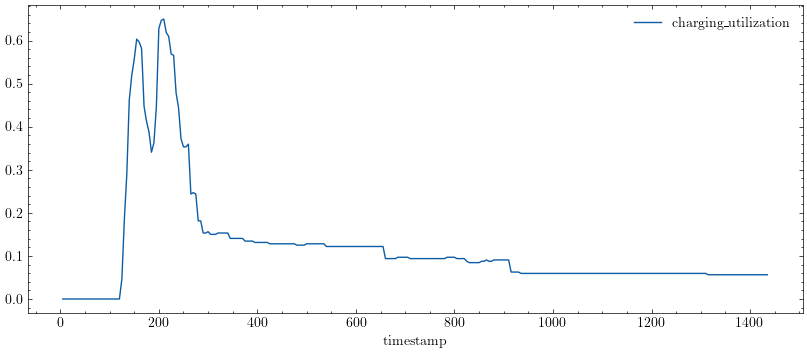

In [114]:
benchmark_no_coordination.plot(x='timestamp', y='charging_utilization', figsize=(10, 4))

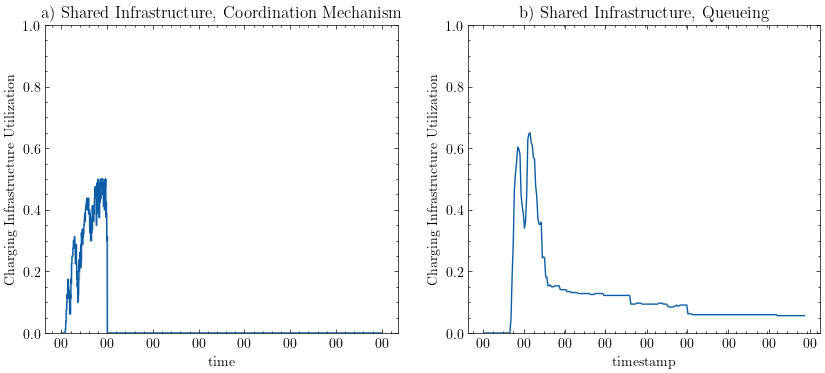

In [115]:
# compare to our scenario
benchmark_no_coordination['time'] = pd.to_datetime(benchmark_no_coordination['timestamp'].apply(SimulationTimeConverter.as_time), format="%H:%M:%S")

fig, ax = plt.subplots(1,2, figsize=(12,4))

sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='system_wide_utilization', ax=ax[0])
ax[0].set_ylabel('Charging Infrastructure Utilization')
ax[0].set_title('a) Shared Infrastructure, Coordination Mechanism')

sns.lineplot(data=benchmark_no_coordination, x='timestamp', y='charging_utilization', ax=ax[1])
ax[1].set_ylabel('Charging Infrastructure Utilization')
ax[1].set_title('b) Shared Infrastructure, Queueing')

for a in ax:
    a.set_ylim(0, 1.0)
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS +  1))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

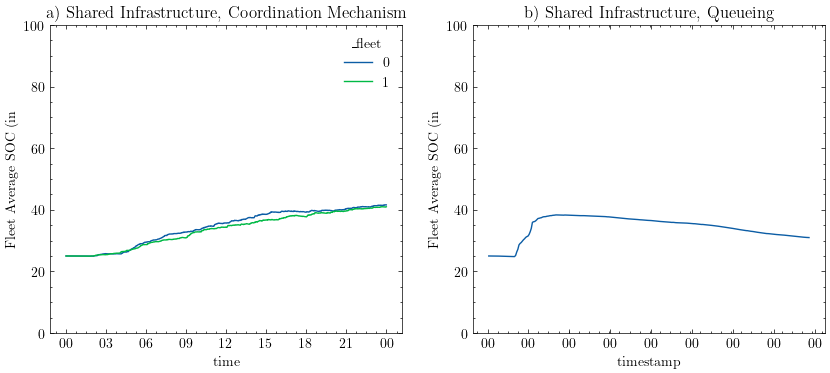

In [29]:
# compare to our scenario
fig, ax = plt.subplots(1,2, figsize=(10,4))

sns.lineplot(data=vehicle_tracking, x='time', y='fleet_average_SOC', hue='_fleet', ax = ax[0])
ax[0].set_ylabel('Fleet Average SOC (in %)')
ax[0].set_title('a) Shared Infrastructure, Coordination Mechanism')

sns.lineplot(data=benchmark_no_coordination, x='timestamp', y='all_vehicles_avg_SOC', ax=ax[1])
ax[1].set_ylabel('Fleet Average SOC (in %)')
ax[1].set_title('b) Shared Infrastructure, Queueing')

for a in ax:
    a.set_ylim(0, 100)
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

In [58]:
benchmark_no_coordination['vehicles_avg_waiting_times'] = benchmark_no_coordination['all_vehicles_waiting_times'].apply(lambda x: np.mean([y[0] for y in eval(x) if len(y) > 0]))

<Axes: xlabel='timestamp', ylabel='vehicles_avg_waiting_times'>

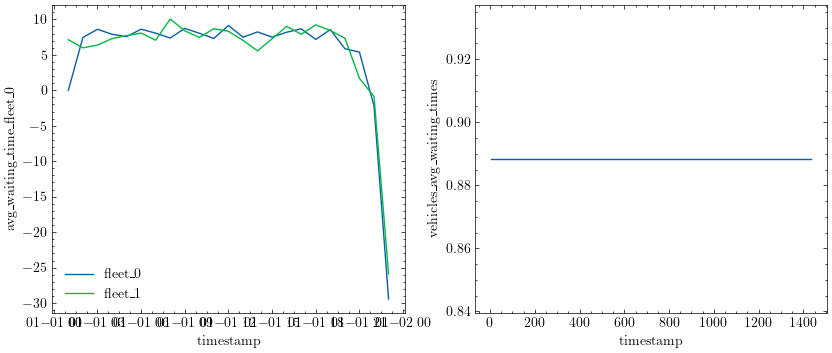

In [59]:
# compare to our scenario
fig, ax = plt.subplots(1,2, figsize=(10,4))

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_0', label='fleet_0', ax=ax[0])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_1', label='fleet_1', ax=ax[0])

sns.lineplot(data=benchmark_no_coordination, x='timestamp', y='vehicles_avg_waiting_times', ax=ax[1])


In [31]:
metrics_no_coordination = pd.read_csv("data/output/benchmarks/end_of_sim_kpi_500.csv")

In [32]:
metrics_no_coordination

,fleet_0_total_fulfilled_trips_ride_hailing,fleet_0_total_missed_trips_ride_hailing,fleet_1_total_fulfilled_trips_ride_hailing,fleet_1_total_missed_trips_ride_hailing,fleet_0_mean_distance_to_charging_station,fleet_1_mean_distance_to_charging_station
0,5291,2425,5225,2340,1672.85863,1732.391686


In [63]:
display(transactions_fleet_0.value_counts('state'))
display(transactions_fleet_1.value_counts('state'))

state
Fulfilled    3974
REFUSED      2176
MISSED        386
Name: count, dtype: int64

state
Fulfilled    4053
REFUSED      2088
MISSED        357
Name: count, dtype: int64

In [66]:
pd.DataFrame([
    {
        'fleet': 0,
        'service_rate_coordination': sum(transactions_fleet_0['state'] == 'Fulfilled') / transactions_fleet_0.shape[0],
        'service_rate_queuing': metrics_no_coordination.at[0, 'fleet_0_total_fulfilled_trips_ride_hailing'] / (metrics_no_coordination.at[0, 'fleet_0_total_fulfilled_trips_ride_hailing'] + metrics_no_coordination.at[0, 'fleet_0_total_missed_trips_ride_hailing'])
    },
    {
        'fleet': 1,
        'service_rate_coordination': sum(transactions_fleet_1['state'] == 'Fulfilled') / transactions_fleet_1.shape[0],
        'service_rate_queuing': metrics_no_coordination.at[0, 'fleet_1_total_fulfilled_trips_ride_hailing'] / (metrics_no_coordination.at[0, 'fleet_1_total_fulfilled_trips_ride_hailing'] + metrics_no_coordination.at[0, 'fleet_1_total_missed_trips_ride_hailing'])
    }    
])

,fleet,service_rate_coordination,service_rate_queuing
0,0,0.608017,0.685718
1,1,0.623730,0.690681


### other stuff

<Axes: xlabel='waiting_time', ylabel='pick_up_time'>

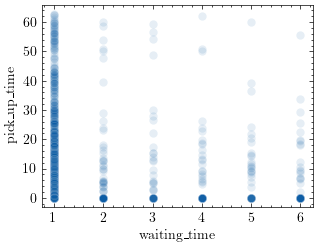

In [68]:
sns.scatterplot(transactions_fleet_0, x='waiting_time', y='pick_up_time', alpha=.1)

In [69]:
transactions_fleet_0['pick_up_time'].describe()

count    6551.000000
mean        4.126147
std         8.132946
min         0.000000
25%         0.000000
50%         1.278793
75%         4.707706
max        62.776211
Name: pick_up_time, dtype: float64